In [1]:
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_table("household_power_consumption.txt", sep = ';')

/var/folders/rx/43tzz06s4zxf192n8h4n3kc00000gn/T/ipykernel_5968/1482020284.py:1: DtypeWarning: Columns (2: Global_active_power, 3: Global_reactive_power, 4: Voltage, 5: Global_intensity, 6: Sub_metering_1, 7: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_table("household_power_consumption.txt", sep = ';')


In [3]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [4]:
print(df.info())
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(6), str(2)
memory usage: 142.5+ MB
None


Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [5]:
cols = [ 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3']
import numpy as np
df[cols] = df[cols].replace('?', np.nan)
df[cols] = df[cols].astype('float32')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float32
 3   Global_reactive_power  float32
 4   Voltage                float32
 5   Global_intensity       float32
 6   Sub_metering_1         float32
 7   Sub_metering_2         float32
 8   Sub_metering_3         float32
dtypes: float32(7), str(2)
memory usage: 87.1 MB


In [7]:
df.isna().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

# replacing nan values with median 

In [8]:
df[cols] = df[cols].fillna(df[cols].median())

In [9]:
df.isna().sum()

Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

In [10]:
df['datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)

In [11]:
df.dtypes
df = df.drop(columns=['Date', 'Time'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Global_active_power    float32       
 1   Global_reactive_power  float32       
 2   Voltage                float32       
 3   Global_intensity       float32       
 4   Sub_metering_1         float32       
 5   Sub_metering_2         float32       
 6   Sub_metering_3         float32       
 7   datetime               datetime64[us]
dtypes: datetime64[us](1), float32(7)
memory usage: 71.2 MB


In [12]:
import numpy as np

df['hour'] = df['datetime'].dt.hour
df['day'] = df['datetime'].dt.day
df['day_of_week'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['year'] = df['datetime'].dt.year

# Cyclical encoding for hour
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24).astype('float32')
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24).astype('float32')

In [13]:
 df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 15 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Global_active_power    float32       
 1   Global_reactive_power  float32       
 2   Voltage                float32       
 3   Global_intensity       float32       
 4   Sub_metering_1         float32       
 5   Sub_metering_2         float32       
 6   Sub_metering_3         float32       
 7   datetime               datetime64[us]
 8   hour                   int32         
 9   day                    int32         
 10  day_of_week            int32         
 11  month                  int32         
 12  year                   int32         
 13  hour_sin               float32       
 14  hour_cos               float32       
dtypes: datetime64[us](1), float32(9), int32(5)
memory usage: 126.7 MB


In [14]:
# First, sort chronologically
df = df.sort_values('datetime').reset_index(drop=True)

# After extracting features and creating lag columns,
# you can remove datetime
df = df.drop(columns=['datetime'])

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 14 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float32
 1   Global_reactive_power  float32
 2   Voltage                float32
 3   Global_intensity       float32
 4   Sub_metering_1         float32
 5   Sub_metering_2         float32
 6   Sub_metering_3         float32
 7   hour                   int32  
 8   day                    int32  
 9   day_of_week            int32  
 10  month                  int32  
 11  year                   int32  
 12  hour_sin               float32
 13  hour_cos               float32
dtypes: float32(9), int32(5)
memory usage: 110.8 MB


In [16]:
from sklearn.preprocessing import RobustScaler

In [17]:
features = df[['Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3']]
new_features = features.sample(frac=0.08, random_state=42)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(new_features)

In [18]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
wcss = []
for i in range(1,11):
    mkm = MiniBatchKMeans(n_clusters=i , batch_size=1024)
    y = mkm.fit_predict(X_scaled)
    wcss.append(mkm.inertia_)
    if (i==3):
        y_sample = mkm.predict(X_scaled)
        score = silhouette_score(X_scaled, y_sample)
        print("Silhouette Score:", score)

wcss    

Silhouette Score: 0.9520787000656128


[11831039.0,
 5835663.5,
 1353464.125,
 1314805.25,
 1256244.625,
 1170527.0,
 1224623.75,
 968666.875,
 907478.5,
 916900.25]

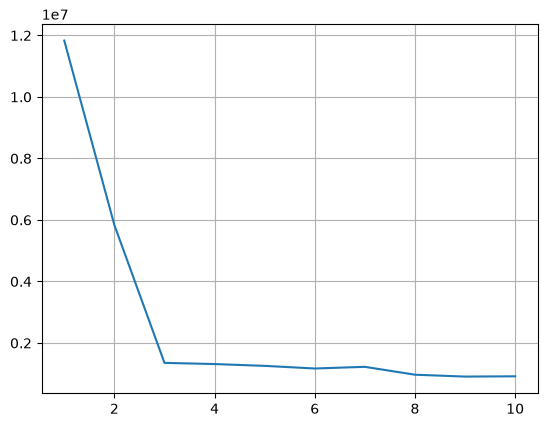

In [19]:
import matplotlib.pyplot as plt
plt.plot(range(1,11),wcss)
plt.grid(True)
plt.show()


# Number of clusters required = 3

In [20]:
# n_clusters = 3
mkm = MiniBatchKMeans(n_clusters = 3,batch_size=4096)
y_means = mkm.fit_predict(features)


In [21]:
df["Cluster_id"] = y_means

In [22]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,day,day_of_week,month,year,hour_sin,hour_cos,Cluster_id
0,4.216,0.418,234.839996,18.4,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2
1,5.360,0.436,233.630005,23.0,0.0,1.0,16.0,17,16,5,12,2006,-0.965926,-0.258819,2
2,5.374,0.498,233.289993,23.0,0.0,2.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2
3,5.388,0.502,233.740005,23.0,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2
4,3.666,0.528,235.679993,15.8,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 15 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float32
 1   Global_reactive_power  float32
 2   Voltage                float32
 3   Global_intensity       float32
 4   Sub_metering_1         float32
 5   Sub_metering_2         float32
 6   Sub_metering_3         float32
 7   hour                   int32  
 8   day                    int32  
 9   day_of_week            int32  
 10  month                  int32  
 11  year                   int32  
 12  hour_sin               float32
 13  hour_cos               float32
 14  Cluster_id             int32  
dtypes: float32(9), int32(6)
memory usage: 118.7 MB


In [24]:
df['Cluster_id'].value_counts()
df.corr()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,day,day_of_week,month,year,hour_sin,hour_cos,Cluster_id
Global_active_power,1.000000,0.247835,-0.399523,0.998891,0.484707,0.435142,0.639772,0.279787,-0.001160,0.063019,-0.031928,-0.038757,-0.187003,-0.109173,0.385963
Global_reactive_power,0.247835,1.000000,-0.112351,0.266900,0.123531,0.139736,0.091057,0.127203,-0.000784,0.067985,0.027341,0.044340,-0.144926,-0.030958,0.037286
Voltage,-0.399523,-0.112351,1.000000,-0.411121,-0.196051,-0.167496,-0.267892,-0.175040,0.023778,-0.021000,-0.015191,0.252606,0.113514,0.172706,-0.185958
Global_intensity,0.998891,0.266900,-0.411121,1.000000,0.489600,0.440909,0.627776,0.280163,-0.001714,0.064439,-0.030707,-0.042931,-0.189431,-0.109219,0.372613
Sub_metering_1,0.484707,0.123531,-0.196051,0.489600,1.000000,0.055201,0.103755,0.107915,-0.006547,0.051681,-0.007265,-0.014327,-0.090083,-0.021716,0.072102
Sub_metering_2,0.435142,0.139736,-0.167496,0.440909,0.055201,1.000000,0.082437,0.086773,0.002096,0.030520,-0.009456,-0.037890,-0.095320,-0.078035,-0.366845
Sub_metering_3,0.639772,0.091057,-0.267892,0.627776,0.103755,0.082437,1.000000,0.113203,-0.005257,0.010311,-0.029820,0.054883,0.001635,-0.276097,0.855085
hour,0.279787,0.127203,-0.175040,0.280163,0.107915,0.086773,0.113203,1.000000,-0.000145,0.000175,0.000216,-0.000696,-0.775939,-0.102110,0.068148
day,-0.001160,-0.000784,0.023778,-0.001714,-0.006547,0.002096,-0.005257,-0.000145,1.000000,0.007873,0.020129,-0.028265,0.000063,-0.000116,-0.007596
day_of_week,0.063019,0.067985,-0.021000,0.064439,0.051681,0.030520,0.010311,0.000175,0.007873,1.000000,-0.000265,-0.000510,-0.000170,0.000077,-0.004986


In [25]:
df['Current_Power'] = df['Global_active_power']
df['Lag_1'] = df['Global_active_power'].shift(1)
df['Lag_2'] = df['Global_active_power'].shift(2) 
df['Target_Next_Hour'] = df['Global_active_power'].shift(-1)
df.dropna(inplace = True)

In [26]:
df.head(10)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,day,day_of_week,month,year,hour_sin,hour_cos,Cluster_id,Current_Power,Lag_1,Lag_2,Target_Next_Hour
2,5.374,0.498,233.289993,23.000000,0.0,2.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,5.374,5.360,4.216,5.388
3,5.388,0.502,233.740005,23.000000,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,5.388,5.374,5.360,3.666
4,3.666,0.528,235.679993,15.800000,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,3.666,5.388,5.374,3.520
5,3.520,0.522,235.020004,15.000000,0.0,2.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,3.520,3.666,5.388,3.702
6,3.702,0.520,235.089996,15.800000,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,3.702,3.520,3.666,3.700
7,3.700,0.520,235.220001,15.800000,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,3.700,3.702,3.520,3.668
8,3.668,0.510,233.990005,15.800000,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,3.668,3.700,3.702,3.662
9,3.662,0.510,233.860001,15.800000,0.0,2.0,16.0,17,16,5,12,2006,-0.965926,-0.258819,2,3.662,3.668,3.700,4.448
10,4.448,0.498,232.860001,19.600000,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,4.448,3.662,3.668,5.412
11,5.412,0.470,232.779999,23.200001,0.0,1.0,17.0,17,16,5,12,2006,-0.965926,-0.258819,2,5.412,4.448,3.662,5.224


In [27]:
df_hourly = df.groupby(['day', 'hour' , 'month','year'], sort=False).agg({
    'Global_active_power': 'mean',
    'Sub_metering_1': 'mean',
    'Sub_metering_2': 'mean',
    'Sub_metering_3': 'mean',
    'day_of_week': 'first', 
    'Cluster_id': lambda x: x.mode()[0] if not x.mode().empty else np.nan
}).reset_index()
df_hourly['Target_Next_Hour'] = df_hourly['Global_active_power'].shift(-1)
df_hourly['Lag_1'] = df_hourly['Global_active_power'].shift(1)
df_hourly['Lag_2'] = df_hourly['Global_active_power'].shift(2)
df_hourly['Current_Power'] = df_hourly['Global_active_power']
df_hourly = df_hourly.dropna()

In [28]:
df_hourly.info()
df_hourly.columns
df_hourly.head()

<class 'pandas.DataFrame'>
RangeIndex: 34586 entries, 2 to 34587
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   day                  34586 non-null  int32  
 1   hour                 34586 non-null  int32  
 2   month                34586 non-null  int32  
 3   year                 34586 non-null  int32  
 4   Global_active_power  34586 non-null  float32
 5   Sub_metering_1       34586 non-null  float32
 6   Sub_metering_2       34586 non-null  float32
 7   Sub_metering_3       34586 non-null  float32
 8   day_of_week          34586 non-null  int32  
 9   Cluster_id           34586 non-null  int32  
 10  Target_Next_Hour     34586 non-null  float32
 11  Lag_1                34586 non-null  float32
 12  Lag_2                34586 non-null  float32
 13  Current_Power        34586 non-null  float32
dtypes: float32(8), int32(6)
memory usage: 1.8 MB


,day,hour,month,year,Global_active_power,Sub_metering_1,Sub_metering_2,Sub_metering_3,day_of_week,Cluster_id,Target_Next_Hour,Lag_1,Lag_2,Current_Power
2,16,19,12,2006,3.400233,0.0,1.433333,16.683332,5,2,3.268567,3.632200,4.189647,3.400233
3,16,20,12,2006,3.268567,0.0,0.000000,16.783333,5,2,3.056467,3.400233,3.632200,3.268567
4,16,21,12,2006,3.056467,0.0,0.416667,17.216667,5,2,2.200133,3.268567,3.400233,3.056467
5,16,22,12,2006,2.200133,0.0,0.133333,4.433333,5,1,2.061600,3.056467,3.268567,2.200133
6,16,23,12,2006,2.061600,0.0,0.083333,0.000000,5,1,1.882467,2.200133,3.056467,2.061600


In [29]:
features = [  'hour', 'day', 'day_of_week', 'month', 'year', 'Cluster_id', 'Current_Power', 'Lag_1', 'Lag_2',
       'Target_Next_Hour']
df1 =  df_hourly[features].copy()



In [30]:
df1.head()

,hour,day,day_of_week,month,year,Cluster_id,Current_Power,Lag_1,Lag_2,Target_Next_Hour
2,19,16,5,12,2006,2,3.400233,3.632200,4.189647,3.268567
3,20,16,5,12,2006,2,3.268567,3.400233,3.632200,3.056467
4,21,16,5,12,2006,2,3.056467,3.268567,3.400233,2.200133
5,22,16,5,12,2006,1,2.200133,3.056467,3.268567,2.061600
6,23,16,5,12,2006,1,2.061600,2.200133,3.056467,1.882467


In [31]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import root_mean_squared_error,r2_score,mean_absolute_error
X = df1.drop(columns=['Target_Next_Hour'])
y = df1['Target_Next_Hour']
# Ensure LightGBM knows Cluster_ID is categorical
X['Cluster_id'] = X['Cluster_id'].astype('category')

# 2. Sequential Time-Series Split (80% for training, 20% for testing)
split_idx = int(len(X) * 0.80)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]


# model selected = XGBoost

In [32]:
import lightgbm as lgb
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_squared_error

# Increased splits to 5 for a more rigorous validation across time
time_splitter = TimeSeriesSplit(n_splits=5)
# model = lgb.LGBMRegressor(random_state=42, n_jobs=-1)

# # Wide and rigorous hyperparameter space
# parameters_to_test = {
#     'num_leaves': [15, 31, 63, 127],
#     'max_depth': [-1, 4, 6, 8, 10],
#     'min_child_samples': [10, 20, 35, 50],     
#     'learning_rate': [0.005, 0.01, 0.03, 0.05, 0.1],
#     'n_estimators': [300, 500, 800, 1000],
#     'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],                
#     'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],         
#     'reg_alpha': [0.0, 0.1, 0.5, 1.0, 5.0, 10.0],           
#     'reg_lambda': [0.0, 0.1, 0.5, 1.0, 5.0, 10.0]           
# }

# RandomizedSearch efficiently explores the massive parameter space
# random_search = RandomizedSearchCV(
#     estimator=model,
#     param_distributions=parameters_to_test,
#     n_iter=30,                     # Tests 30 diverse combinations
#     cv=time_splitter,
#     scoring='neg_root_mean_squared_error',                  
#     random_state=42,
#     n_jobs=-1
# )




# best parameters found

In [38]:
from lightgbm import LGBMRegressor
lgbm_model = LGBMRegressor(
    subsample=0.7,
    reg_lambda=0.1,
    reg_alpha=10.0,
    num_leaves=15,
    n_estimators=800,
    min_child_samples=50,
    max_depth=-1,
    learning_rate=0.03,
    colsample_bytree=0.9,
    force_row_wise=True,
    verbosity=-1,
    random_state=42,
    n_jobs=-1
)
lgbm_model.fit(X_train, y_train)



# Generate predictions
train_preds = lgbm_model.predict(X_train)
test_preds = lgbm_model.predict(X_test)

# Calculate metrics
train_r2 = r2_score(y_train, train_preds)
test_r2 = r2_score(y_test, test_preds)
rmse = np.sqrt(mean_squared_error(y_test, test_preds))

# Output clean evaluation scores
print(f"Train R2: {train_r2:.4f}")
print(f"Test R2: {test_r2:.4f}")
print(f"Test RMSE: {rmse:.4f}")


Train R2: 0.6972
Test R2: 0.5971
Test RMSE: 0.4615


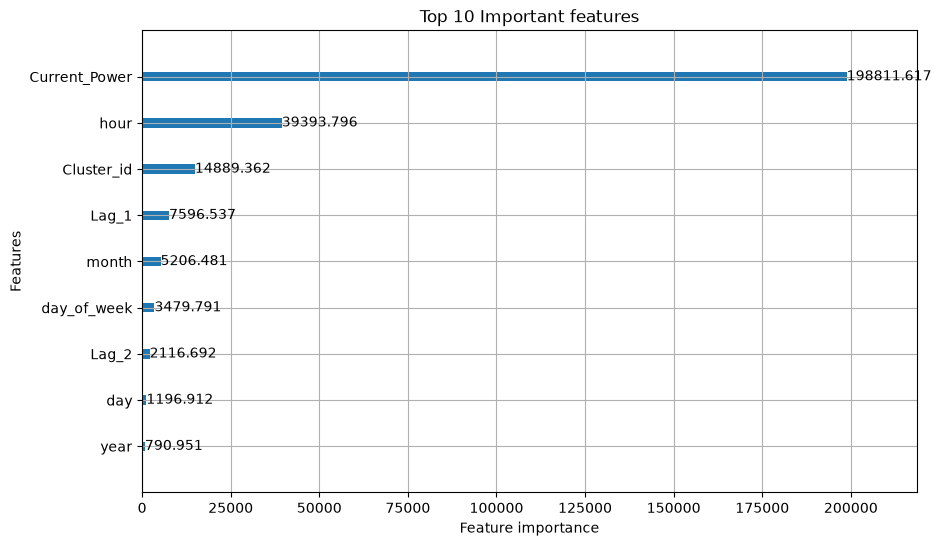

In [40]:
import lightgbm as lgb
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
lgb.plot_importance(lgbm_model, max_num_features=10, importance_type='gain', ax=plt.gca())
plt.title("Top 10 Important features")
plt.show()

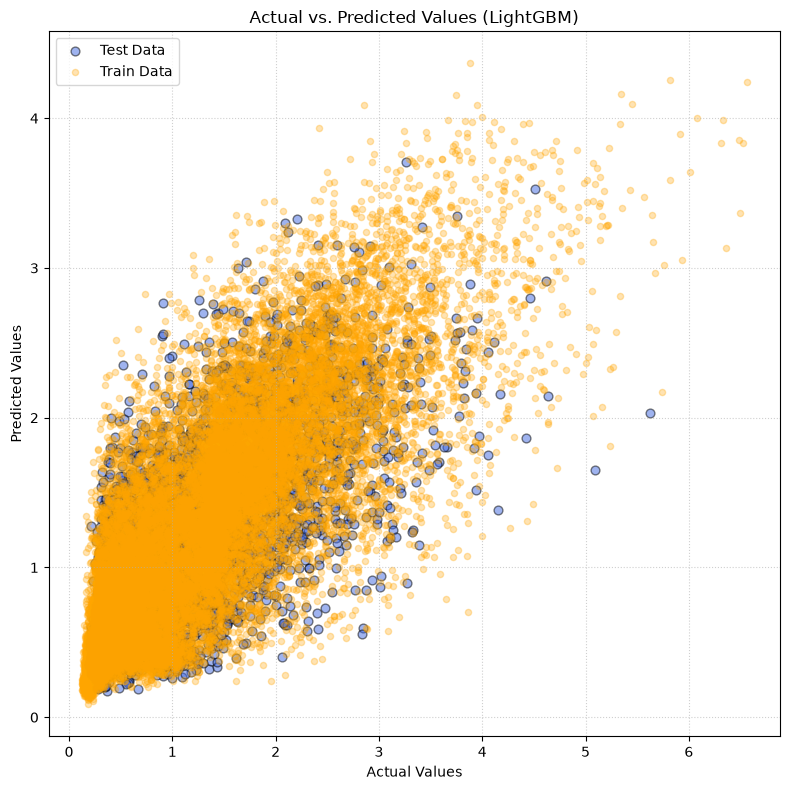

In [41]:
import matplotlib.pyplot as plt
# 1. Generate predictions for both sets
train_preds = lgbm_model.predict(X_train)
test_preds = lgbm_model.predict(X_test)
# 2. Set up the plot figure (square aspect ratio works best for actual vs predicted)
plt.figure(figsize=(8, 8))
# Scatter plots for Train and Test sets
plt.scatter(y_test, test_preds, alpha=0.5, color='royalblue', label='Test Data', edgecolor='k', s=40)
plt.scatter(y_train, train_preds, alpha=0.3, color='orange', label='Train Data', s=20)
# 4. Format and label the plot
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values (LightGBM)')
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# import joblib
# joblib.dump(best_model, 'lightgbm_time_series_model.pkl')
# print("Model successfully saved!")